# ACC_Modeling: Physics-Informed Sparse Identification of Vehicle Dynamics
**Stage 2 Milestone — Whole-Vehicle Planar Force & Friction-Ellipse Formulation ($[\delta, \dot{\delta}, a_y, a_x, v, \eta_P] \to \dot{r}$)**

This notebook demonstrates the modular `ACC_Modeling` (`src`) pipeline evaluated on **200 Hz ACC MoTeC telemetry** at **Circuit de Barcelona-Catalunya** for two controlled Audi R8 chassis:
- **High-Downforce Prototype**: Audi R8 LMS GT3 Evo II (`configs/cars/audi_r8_gt3_evo2/vehicle.yaml`)
- **Mechanical-Grip Baseline**: Audi R8 LMS GT4 (`configs/cars/audi_r8_gt4/vehicle.yaml`)

### Pipeline Overview
1. **Data Curation**: Unit-aware SI conversion, continuous session trimming (`SPEED >= 100 km/h` for practice; `first_beacon` for race), Savitzky-Golay (`window=41, poly=3`) smoothing & analytical differentiation ($\dot{r}, \dot{a}_y$), and tire-pressure grip factor $\eta_P(t)$.
2. **Planar Force Identification (`PlanarForceLibrary`)**: PySINDy `STLSQ` regression on the 8-term physics-informed yaw-acceleration library.
3. **Statistical Stress-Testing & Physical Corner Mapping**: Residual Gaussianity & Type-I Omission Sweep, Moving-Block Bootstrap (95% CI & $p$-values), and Race $>5\sigma_0$ outlier georeferencing.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

if Path.cwd().name == "notebooks":
    os.chdir("..")

from src.cli import run_pipeline
print("Working directory:", Path.cwd())

Working directory: /mnt/c/LocalD/ACC_Modeling


## 1. Audi R8 LMS GT3 Evo II — Practice Identification & Race Stress-Test

In [2]:
gt3_report = run_pipeline("configs/experiments/stage2_planar_force/barcelona__audi_r8_gt3_evo2__r8_A.yaml")
print("Identified ODE:", gt3_report["equation"])
print(f"Clean Practice: R^2 = {gt3_report['clean_metrics']['r2']:.4f}, RMSE = {gt3_report['clean_metrics']['rmse']:.4f} rad/s^2")
print(f"Race Stress-Test: R^2 = {gt3_report['race_metrics']['r2']:.4f}, Within ±3σ = {gt3_report['race_metrics']['diagnostics']['within_3sigma_pct']:.2f}%")

INFO: Running experiment: stage2_barcelona_gt3_r8_A (Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=16.510s, 218865 -> 215563 rows)


INFO: Identified ODE: dr/dt = +0.72311 * delta +0.09402 * delta_dot -1.58741 * r +8.81799 * r/v -2.57354 * (a_y-v*r)/v +0.01778 * a_y_dot +0.00032 * a_y*|a_x|/eta_P^2 -0.11042 * delta*|delta|


INFO: Clean Practice R^2=0.3895 | RMSE=0.7228 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Trimmed at first_beacon t=85.184s (148594 -> 131557 rows)


INFO: Race Stress-Test R^2=0.3919 | Within ±3σ=98.62% | >5σ=474


INFO: Artifacts saved to outputs/stage2_barcelona_gt3_r8_A


Identified ODE: dr/dt = +0.72311 * delta +0.09402 * delta_dot -1.58741 * r +8.81799 * r/v -2.57354 * (a_y-v*r)/v +0.01778 * a_y_dot +0.00032 * a_y*|a_x|/eta_P^2 -0.11042 * delta*|delta|
Clean Practice: R^2 = 0.3895, RMSE = 0.7228 rad/s^2
Race Stress-Test: R^2 = 0.3919, Within ±3σ = 98.62%


In [3]:
display(Markdown("### GT3 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(gt3_report["bootstrap"]["terms"]))

display(Markdown("### GT3 Type-I Error (Omission) Sweep — Clean Practice"))
display(pd.DataFrame(gt3_report["clean_metrics"]["diagnostics"]["omission_sweep"]))

display(Markdown("### GT3 Race >5σ Anomaly Corner Mapping"))
display(pd.Series(gt3_report["race_metrics"]["corner_anomalies"], name="Anomaly Frames").to_frame())

### GT3 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,delta,0.723107,0.731148,0.092914,0.562700,0.924261,7.782521,4.125463e-14
1,delta_dot,0.094021,0.093770,0.010596,0.072962,0.115847,8.873032,1.275616e-17
2,r,-1.587414,-1.574804,0.219682,-2.020827,-1.199633,-7.225955,1.875495e-12
3,r/v,8.817991,7.996351,5.520765,-1.215694,18.424715,1.597241,1.108451e-01
4,(a_y-v*r)/v,-2.573542,-2.578133,0.261119,-3.105092,-2.105541,-9.855811,4.672468e-21
5,a_y_dot,0.017780,0.017794,0.001093,0.015640,0.020128,16.267964,4.737872e-48
6,a_y*|a_x|/eta_P^2,0.000320,0.000326,0.000140,0.000039,0.000596,2.277200,2.319668e-02
7,delta*|delta|,-0.110423,-0.111434,0.026888,-0.173794,-0.067791,-4.106720,4.689071e-05


### GT3 Type-I Error (Omission) Sweep — Clean Practice

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,68400.405006,41930,31.731051,19.451390
1,2.0,9808.173386,10369,4.550026,4.810195
2,2.5,2677.148173,6175,1.241933,2.864592
3,3.0,581.976139,4010,0.269980,1.860245
4,3.5,100.292444,2672,0.046526,1.239545
5,4.0,13.654296,1822,0.006334,0.845229
6,5.0,0.123583,867,0.000057,0.402203


### GT3 Race >5σ Anomaly Corner Mapping

,Anomaly Frames
T9 Campsa,182
T11-T14 Sector 3,134
T4 Repsol,75
T7-T8 Chicane,34
T10 La Caixa,27
T5 Seat,22


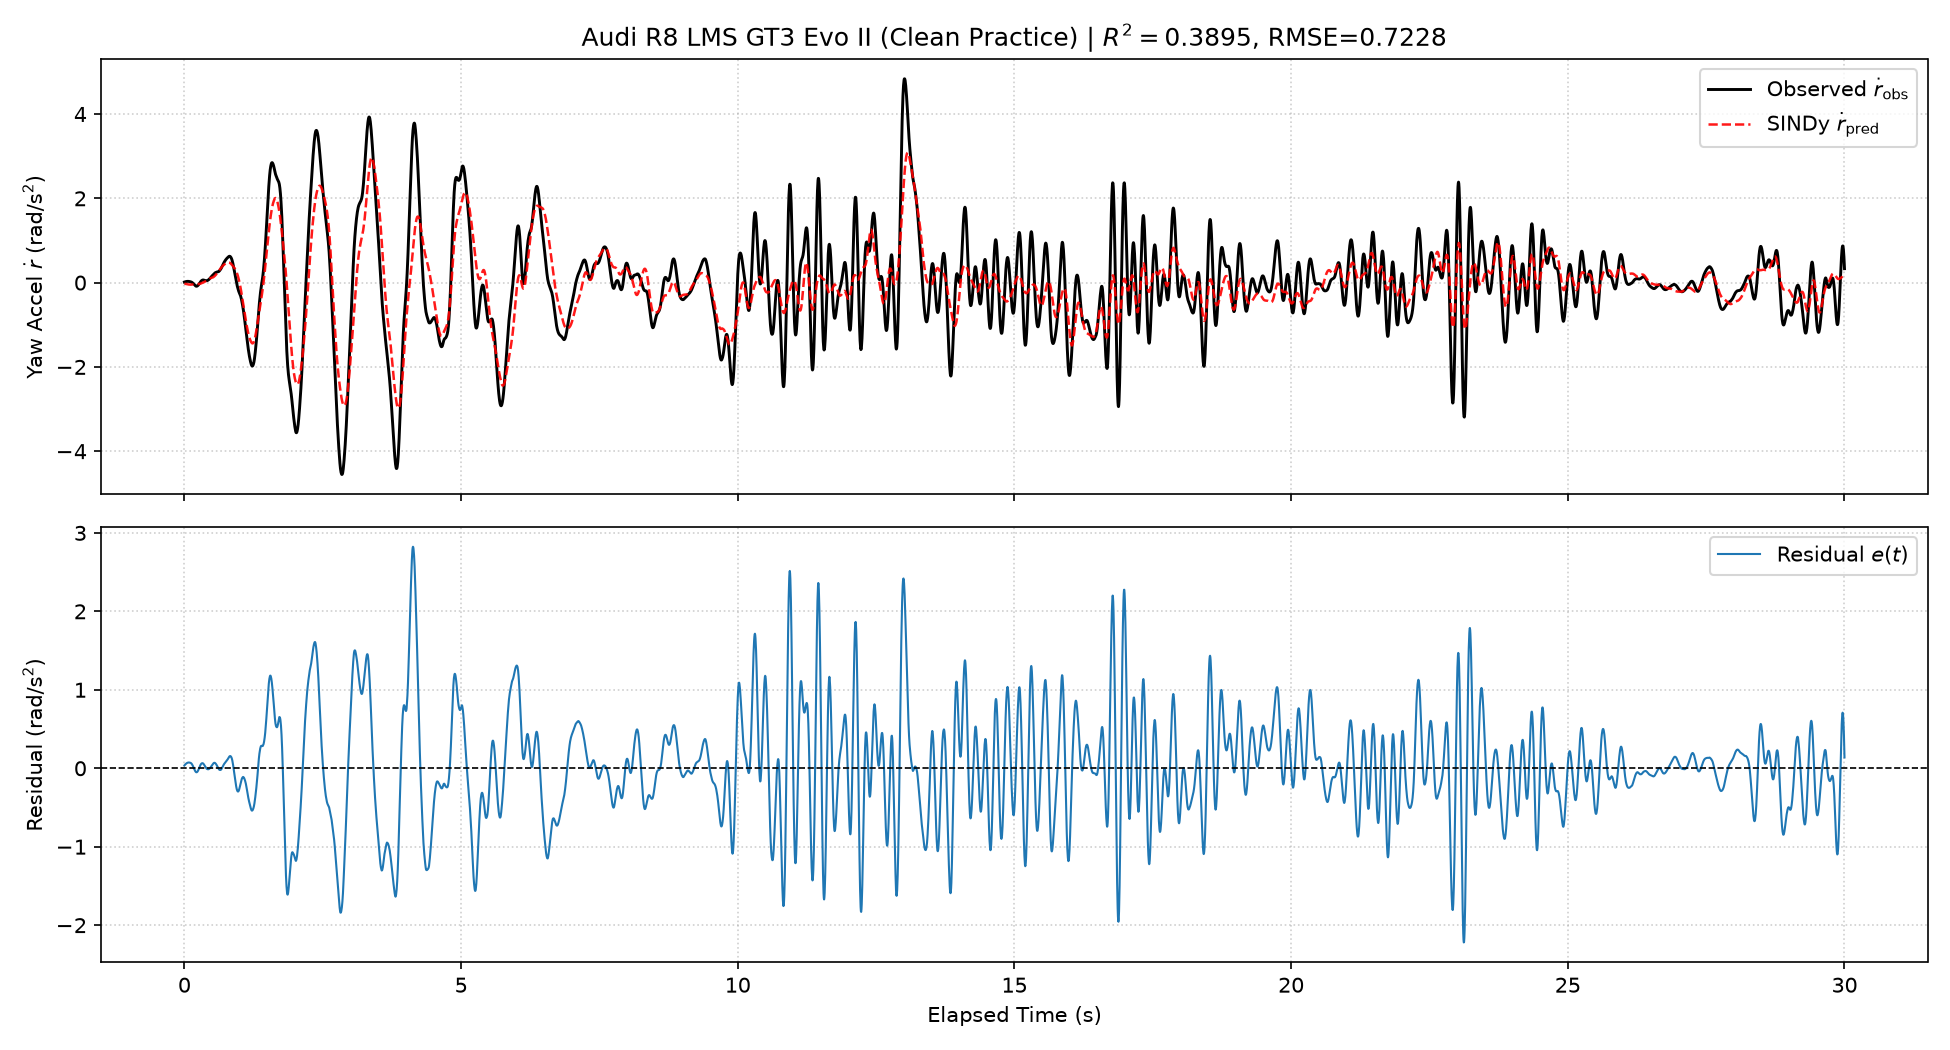

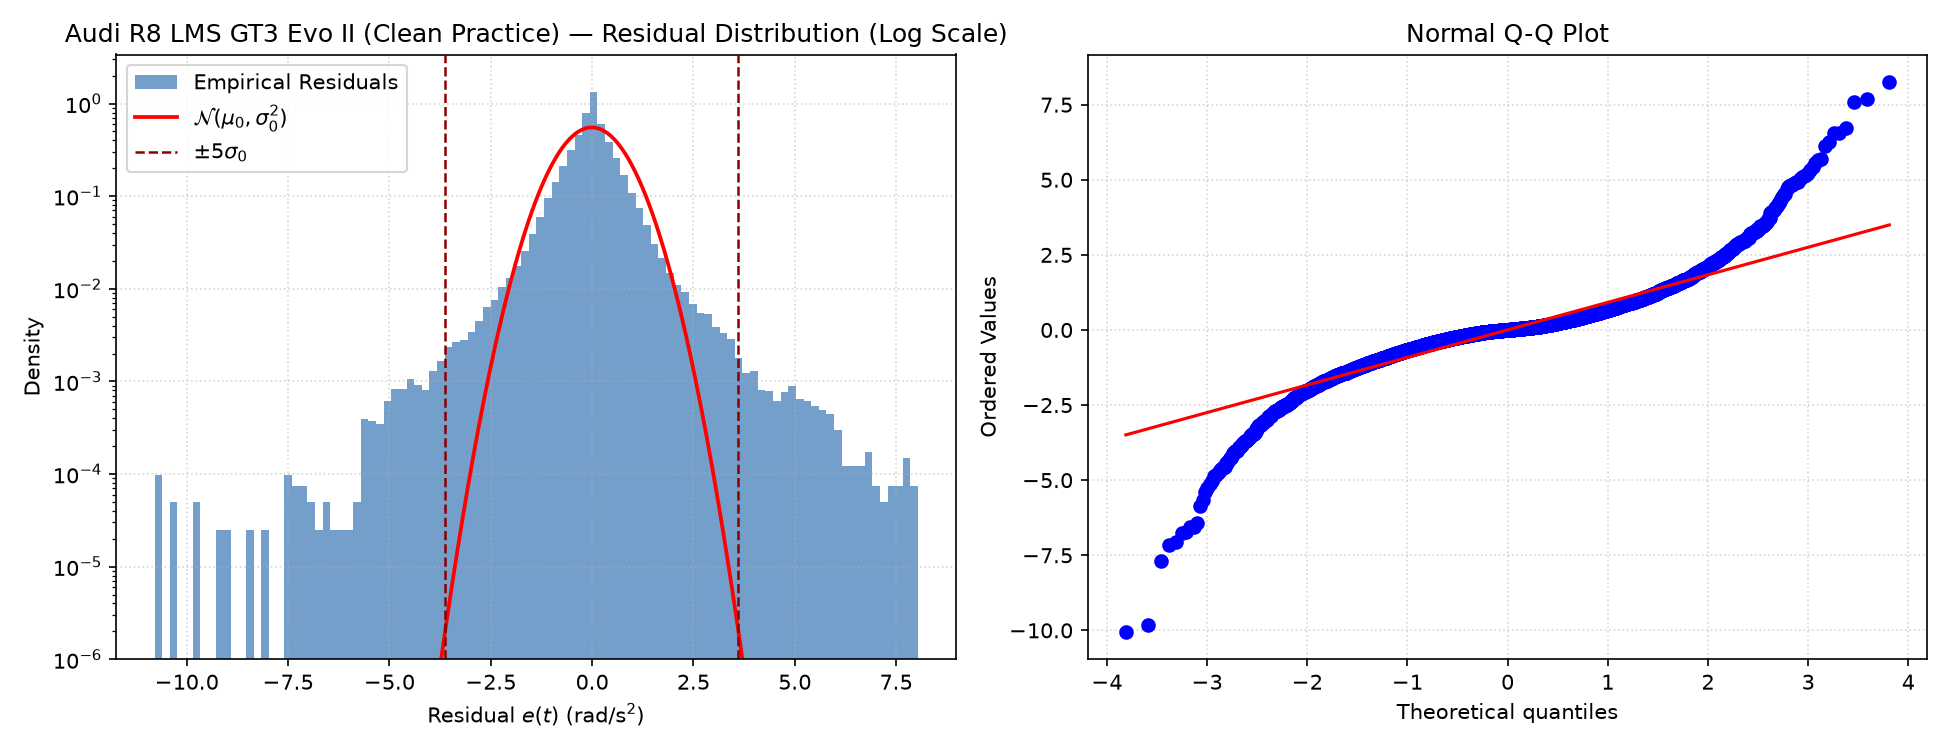

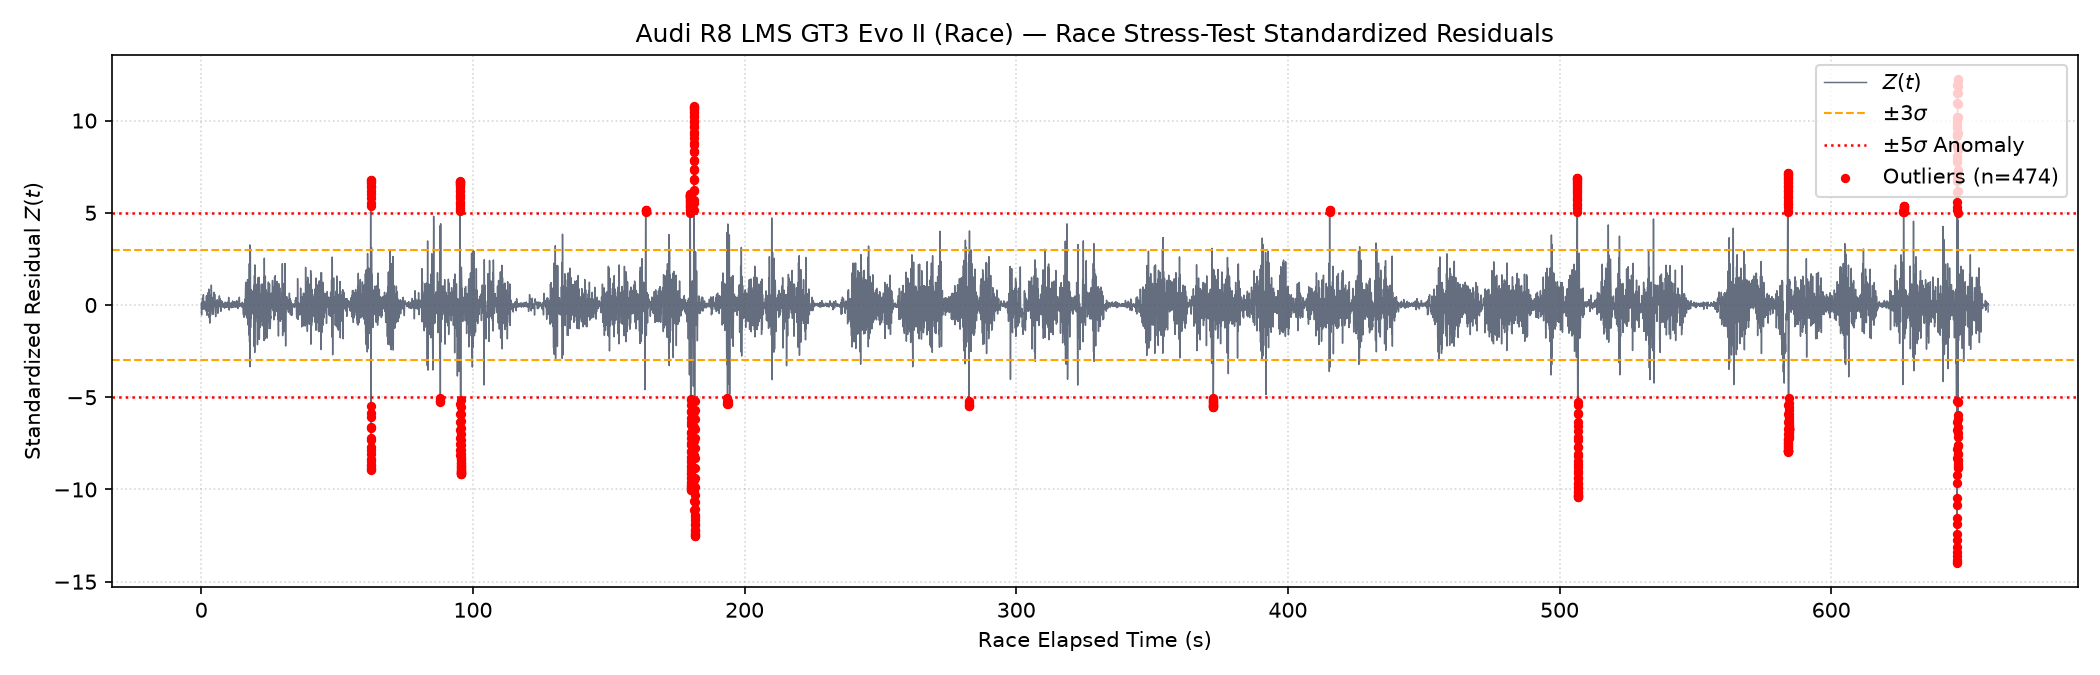

In [4]:
gt3_out = Path("outputs/stage2_barcelona_gt3_r8_A")
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png", "race_anomaly_trace.png"]:
    display(Image(filename=str(gt3_out / img_name)))

## 2. Audi R8 LMS GT4 — Mechanical-Grip Baseline

In [5]:
gt4_report = run_pipeline("configs/experiments/stage2_planar_force/barcelona__audi_r8_gt4__a1.yaml")
print("Identified ODE:", gt4_report["equation"])
print(f"Clean Practice: R^2 = {gt4_report['clean_metrics']['r2']:.4f}, RMSE = {gt4_report['clean_metrics']['rmse']:.4f} rad/s^2")
print(f"Race Stress-Test: R^2 = {gt4_report['race_metrics']['r2']:.4f}, Within ±3σ = {gt4_report['race_metrics']['diagnostics']['within_3sigma_pct']:.2f}%")

INFO: Running experiment: stage2_barcelona_gt4_a1 (Audi R8 LMS GT4 @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=25.525s, 256828 -> 251723 rows)


INFO: Identified ODE: dr/dt = +0.94844 * delta -0.00900 * delta_dot -2.18861 * r +15.46855 * r/v -0.81513 * (a_y-v*r)/v +0.02631 * a_y_dot -0.00000 * a_y*|a_x|/eta_P^2 -0.22194 * delta*|delta|


INFO: Clean Practice R^2=0.4214 | RMSE=0.5464 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Trimmed at first_beacon t=65.664s (155093 -> 141960 rows)


INFO: Race Stress-Test R^2=0.3581 | Within ±3σ=98.05% | >5σ=825


INFO: Artifacts saved to outputs/stage2_barcelona_gt4_a1


Identified ODE: dr/dt = +0.94844 * delta -0.00900 * delta_dot -2.18861 * r +15.46855 * r/v -0.81513 * (a_y-v*r)/v +0.02631 * a_y_dot -0.00000 * a_y*|a_x|/eta_P^2 -0.22194 * delta*|delta|
Clean Practice: R^2 = 0.4214, RMSE = 0.5464 rad/s^2
Race Stress-Test: R^2 = 0.3581, Within ±3σ = 98.05%


In [6]:
display(Markdown("### GT4 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(gt4_report["bootstrap"]["terms"]))

display(Markdown("### GT4 Type-I Error (Omission) Sweep — Clean Practice"))
display(pd.DataFrame(gt4_report["clean_metrics"]["diagnostics"]["omission_sweep"]))

display(Markdown("### GT4 Race >5σ Anomaly Corner Mapping"))
display(pd.Series(gt4_report["race_metrics"]["corner_anomalies"], name="Anomaly Frames").to_frame())

### GT4 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,delta,9.484387e-01,9.833402e-01,1.233922e-01,7.461717e-01,1.231286e+00,7.686376,8.100450e-14
1,delta_dot,-8.999626e-03,-1.045894e-02,1.074692e-02,-3.173545e-02,8.926257e-03,-0.837415,4.027605e-01
2,r,-2.188615e+00,-2.268107e+00,3.384284e-01,-2.969553e+00,-1.587025e+00,-6.466995,2.386305e-10
3,r/v,1.546855e+01,1.681609e+01,6.461787e+00,3.760248e+00,2.896118e+01,2.393850,1.704083e-02
4,(a_y-v*r)/v,-8.151318e-01,-8.352020e-01,2.463132e-01,-1.327504e+00,-3.510549e-01,-3.309331,1.002798e-03
5,a_y_dot,2.631254e-02,2.633410e-02,1.708118e-03,2.320555e-02,2.986412e-02,15.404406,4.398358e-44
6,a_y*|a_x|/eta_P^2,-2.872839e-09,-1.664912e-09,4.841939e-09,-1.477954e-08,4.404236e-09,-0.593324,5.532332e-01
7,delta*|delta|,-2.219426e-01,-2.394329e-01,5.880916e-02,-3.529968e-01,-1.314840e-01,-3.773946,1.799974e-04


### GT4 Type-I Error (Omission) Sweep — Clean Practice

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,79874.352971,50380,31.731051,20.014063
1,2.0,11453.462929,10932,4.550026,4.342869
2,2.5,3126.231170,5739,1.241933,2.279887
3,3.0,679.600764,3347,0.269980,1.329636
4,3.5,117.116179,2211,0.046526,0.878346
5,4.0,15.944760,1621,0.006334,0.643962
6,5.0,0.144314,938,0.000057,0.372632


### GT4 Race >5σ Anomaly Corner Mapping

,Anomaly Frames
T11-T14 Sector 3,414
T3 Renault,181
T7-T8 Chicane,96
T10 La Caixa,86
T5 Seat,48


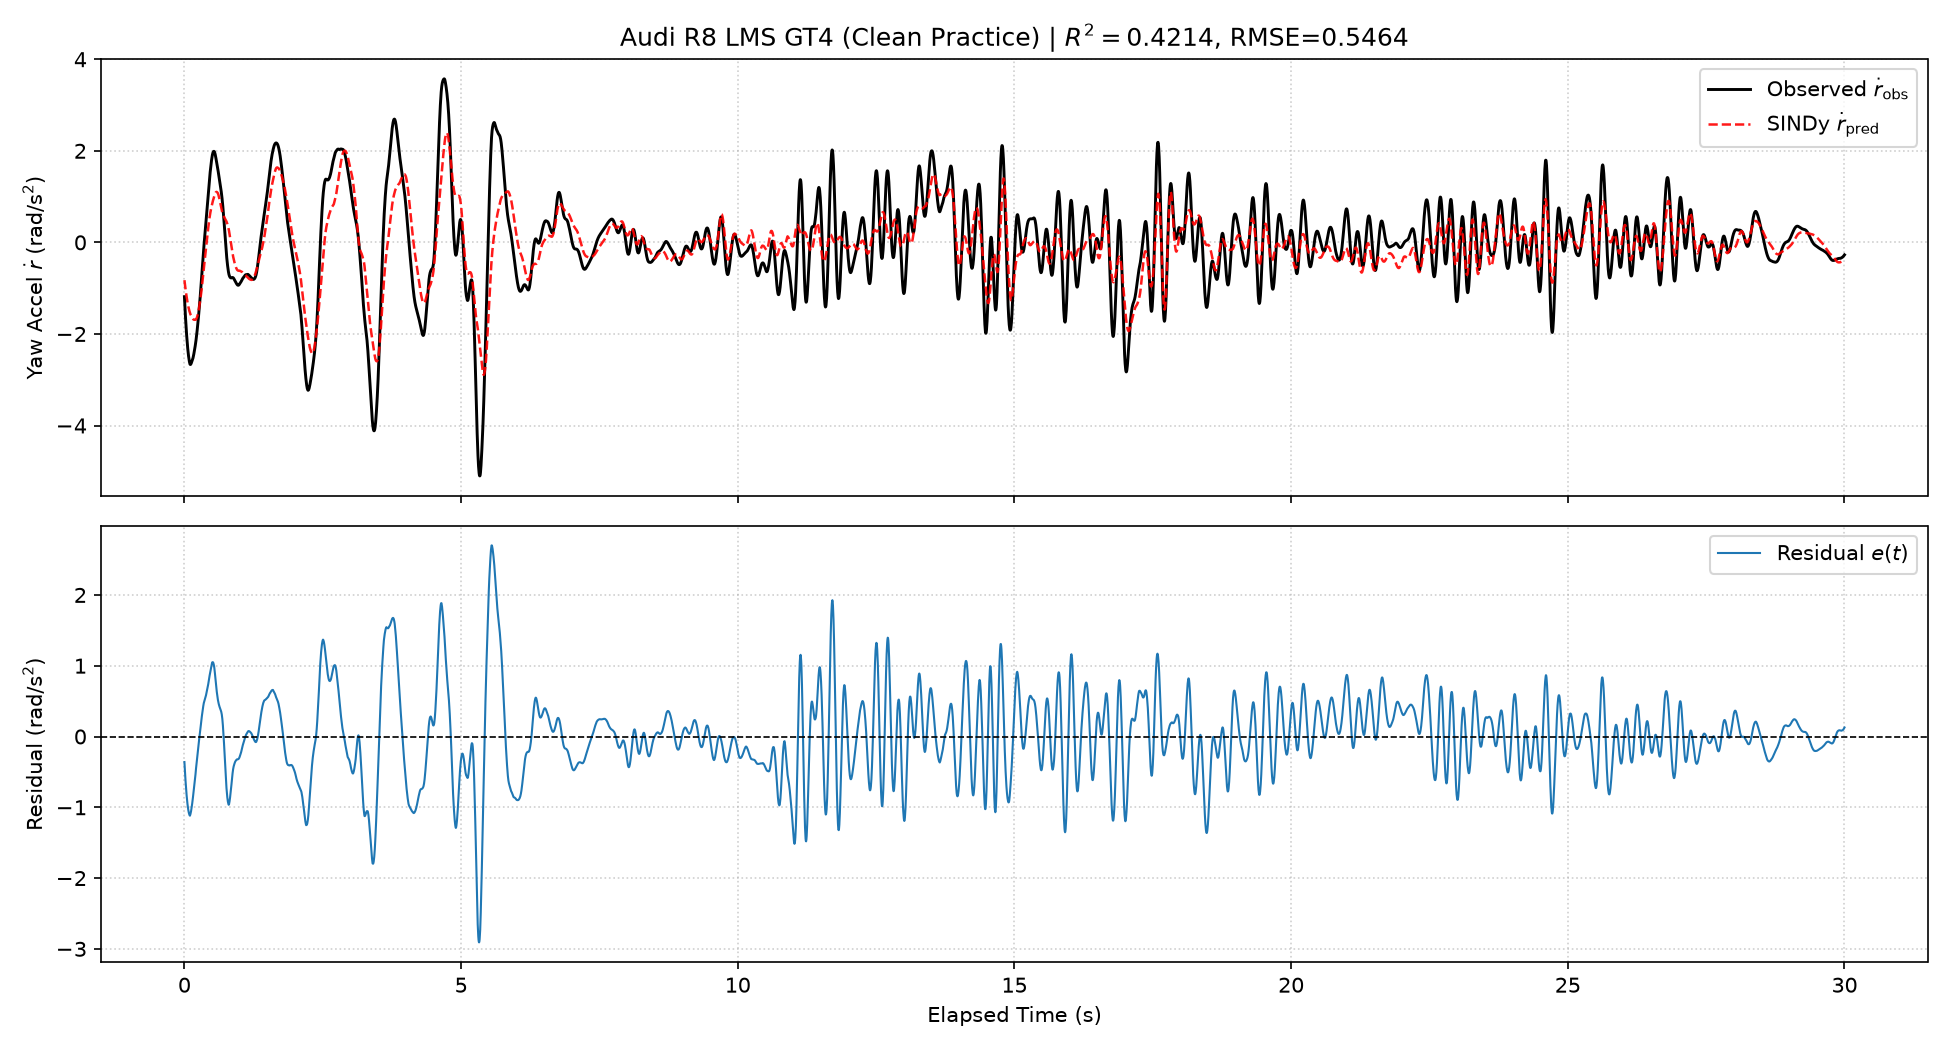

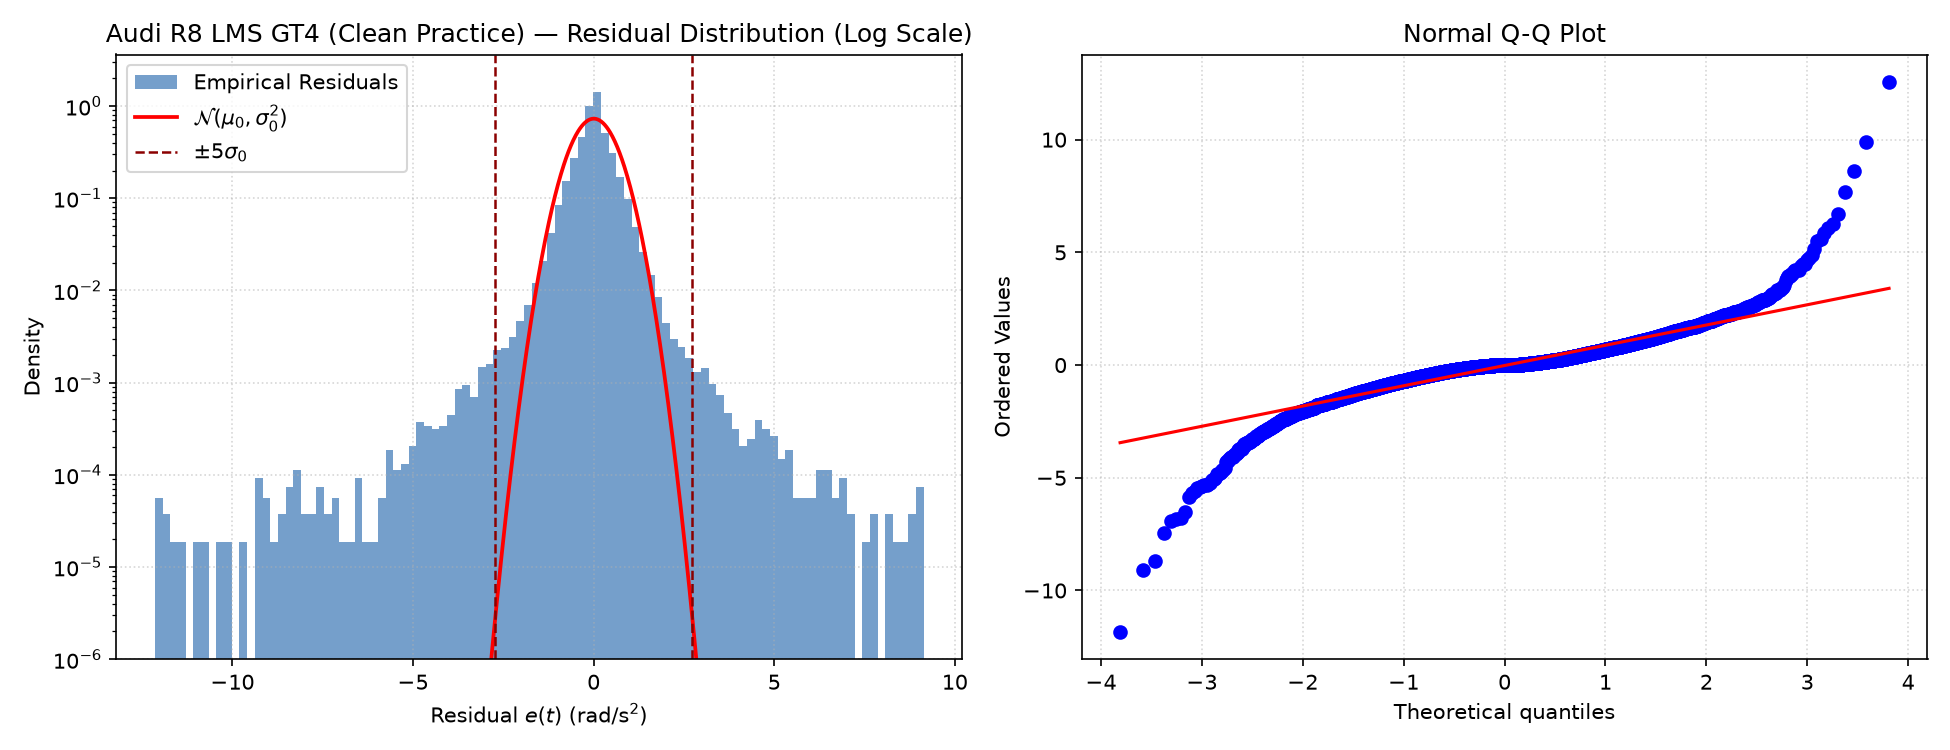

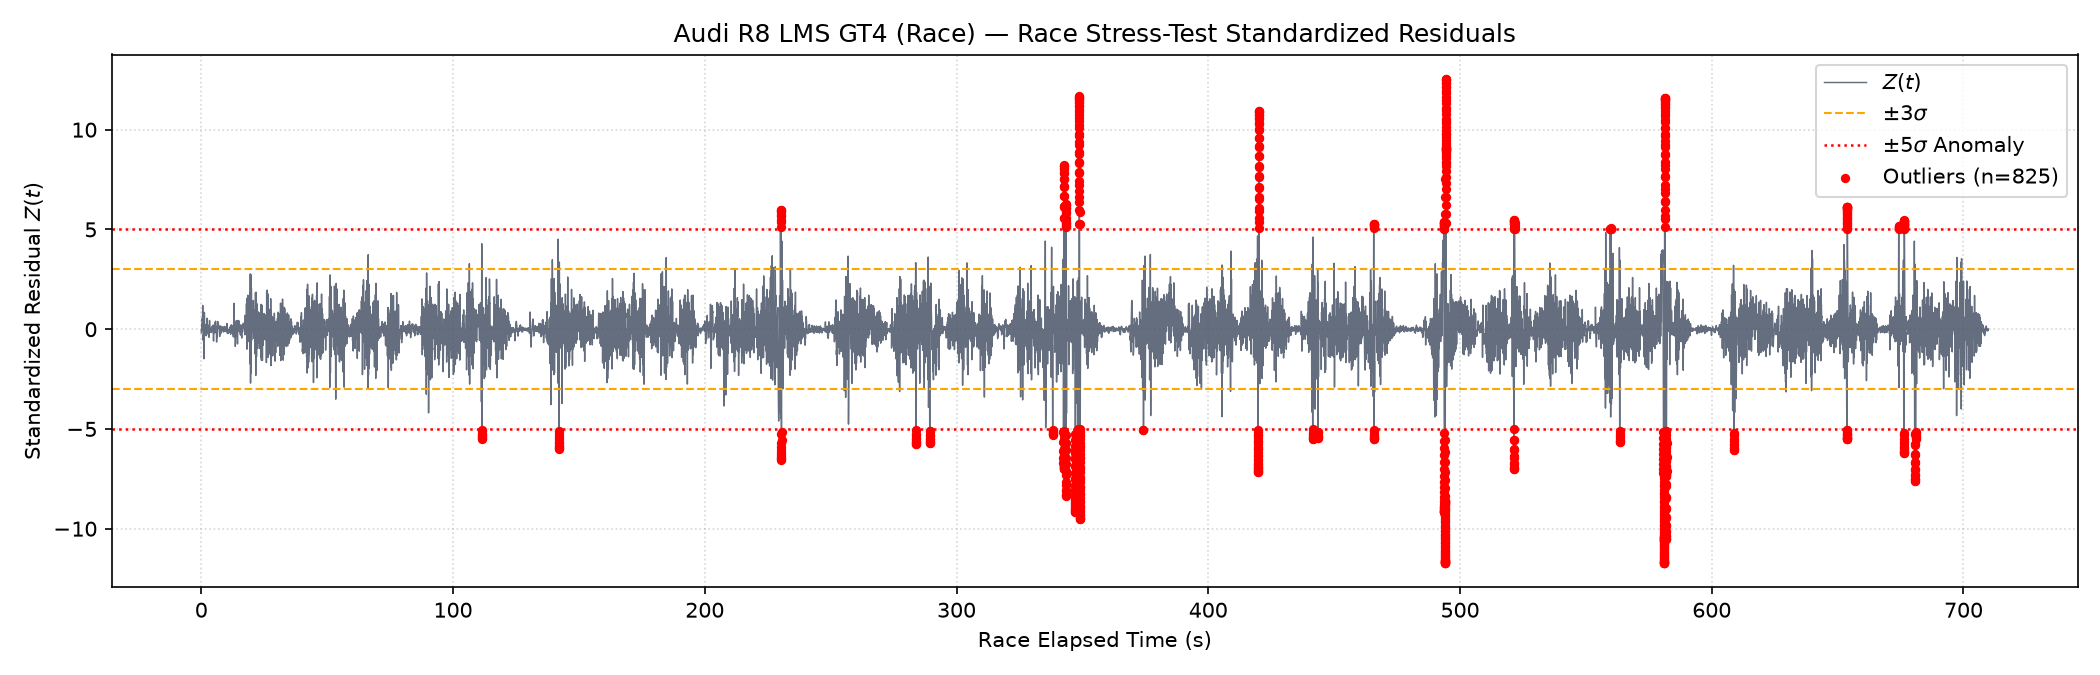

In [7]:
gt4_out = Path("outputs/stage2_barcelona_gt4_a1")
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png", "race_anomaly_trace.png"]:
    display(Image(filename=str(gt4_out / img_name)))